# Welcome to Jupyter!
### *Introduction to jupyter notebooks for bioimage analysis*

We are going to cover some foundational concepts about variables, arrays, and loops, before delving into more complex functions with napari.

*Sara Salgueiro Torres (sara.salgueirotorres@crick.ac.uk)*

---

Modified from material from the *Introduction to Image Analysis* RMS workshop. Original script from *Stefania Marcotti (Francis Crick Institute)*.

*CC-BY-SA-4.0 license: creativecommons.org/licenses/by-sa/4.0/*

---


## Variables

We can use any Python interpreter as a calculator

In [2]:
3 + 2 * 5

13

This is great but not very interesting. To do anything useful with data, we need to assign its value to a variable. For example, we can assign the value `60` to the variable `weight_kg` and the value `1.7` to the variable `height_m`:

In [3]:
weight_kg = 60
height_m = 1.7

In [4]:
print('The weight in kilograms is', weight_kg, 'kg')
print('The height in meters is', height_m, 'm')

The weight in kilograms is 60 kg
The height in meters is 1.7 m


Or we could assign the string `Frida` to the variable `name`, and the string `Kahlo` to the variable `surname`:

In [5]:
name = 'Frida'
surname = 'Kahlo'

In [6]:
print('Their name is', name, surname)

Their name is Frida Kahlo


Variables can have different types: they can be integers, floats, or strings

In [7]:
type(weight_kg)

int

In [8]:
type(height_m)

float

In [9]:
type(name)

str

<div style="background-color:#A468CC; border-radius: 5px; padding: 10pt"><strong>Note</strong> Not all operations are allowed on variables with different types!</div>

In [10]:
weight_kg + name

TypeError: unsupported operand type(s) for +: 'int' and 'str'

In [11]:
weight_str = str(weight_kg)

In [13]:
print('weight_str: ', weight_str)
print('name: ', name)
print('weight_str + name: ', weight_str + name)

weight_str:  60
name:  Frida
weight_str + name:  60Frida


We can perform operations between variables. For example, we could convert the weight from kg to lb:

In [14]:
weight_lb = 2.2 * weight_kg

In [15]:
print('The weight converted in pounds is', weight_lb)

The weight converted in pounds is 132.0


Or create a new variable `full_name` that joins the `name` and `surname` with a space in the middle:

In [16]:
full_name = name + ' ' + surname

In [17]:
print('Their full name is', full_name)

Their full name is Frida Kahlo


Variables can also be Boolean (`True`/`False`)

In [18]:
condition_height = height_m > 1.9
print(condition_height)

False


In [19]:
condition_weight = weight_kg > 10
print(condition_weight)

True


And we can test for equality with `==` and `!=` similarly to Fiji 

In [20]:
weight_lb == 2.2 * weight_kg

True

In [21]:
weight_kg != weight_lb

True

## Arrays

We can store a series of datapoints in an array. There are many ways to do this in Python; however, today we are going to use [Numpy](https://numpy.org/), which is a package that makes scientific computing relatively easy.

When we want to use a module or a package in Python, we need to import it (we use the keywork `import`). We can also import specific functions by using the syntax [`from` module `import` function], if we only want to load a small subset of the available functions. Additionally, we can define aliases for modules' names with the keyword `as`.

In [22]:
import numpy as np

We can create a 1-dimensional array `array1D` like this:

In [23]:
array1D = np.array([2, 5, 8])
print(array1D)

[2 5 8]


In [24]:
array1D_str = np.array(['a','b','c','d','e'])
print(array1D_str)

['a' 'b' 'c' 'd' 'e']


We can interrogate the length of the array with the keyword `len`:

In [25]:
print('The array contains', len(array1D), 'values')
print('The array contains', len(array1D_str), 'letters')

The array contains 3 values
The array contains 5 letters


And we can access specific positions of the array by using the `[]` notation. Please note that Python starts counting from zero!!

In [26]:
print(array1D[0])
print(array1D[2])
print(array1D_str[0])
print(array1D_str[3])

2
8
a
d


<div style="background-color:#A468CC; border-radius: 5px; padding: 10pt"><strong>Note</strong> We can only access elements within the bounds of the array</div>

In [27]:
print(array1D[10])

IndexError: index 10 is out of bounds for axis 0 with size 3

We can also create arrays with more dimensions:

In [28]:
array2D = np.array([[1, 2, 3], [5, 7, 11]])
print(array2D)

[[ 1  2  3]
 [ 5  7 11]]


And interrogate their dimensions with the function `shape`:

In [29]:
print('The array has these dimensions (rows, columns):', array2D.shape)

The array has these dimensions (rows, columns): (2, 3)


To access specific positions in a n-dimensional array, we need to specify n positions. For a 2-dimensional array, the first value specifies the row, while the second specifies the column.
![](./assets/python-zero-index.svg)

In [30]:
print(array2D[0,0])
print(array2D[1,2])

1
11


Otherwise the full row is returned:

In [31]:
print(array2D[0])

[1 2 3]


We can rearrange the dimensions of an array by using the `numpy` function `transpose` (API [here](https://numpy.org/doc/stable/reference/generated/numpy.transpose.html)) :

In [32]:
new_array2D = np.transpose(array2D)
print(new_array2D)

[[ 1  5]
 [ 2  7]
 [ 3 11]]


In [33]:
print('The new array has these dimensions (rows, columns):', new_array2D.shape)

The new array has these dimensions (rows, columns): (3, 2)


### Loops

We might want to perform an operation multiple times, on all elements of an array or on all files in a folder. To do this we have to setup a recurring operation with a loop.

A `while` loop allows code to be executed repeatedly based on a condition

![](./assets/while-loop-diagram.svg)

In [10]:
countdown = 10

while countdown > 0:    
    print(countdown)
    countdown = countdown-1 

10
9
8
7
6
5
4
3
2
1


A `for` loop repeatedly runs a section of code until a condition is satisfied

![](./assets/for-loop-diagram.svg)

The `range()` function is very useful for loops. It returns a sequence of evenly-spaced integer values. They can define the sequence of elements over which the iterations are performed. <br>
For example, we can use it to create a sequence of whole numbers up to 10:

In [32]:
print(list(range(10)))

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


In [ ]:
# for loop anatomy 
for <variable> in <sequence>:
    <INDENTED code that runs once per item>

Let's run our our first `for` loops:

In [33]:
countdown = 10

for count in range(countdown): 
    current_count = countdown - count
    print(current_count)

10
9
8
7
6
5
4
3
2
1


Instead of numbers _standing in_ for the items, we can loop over the items themselves. Each pass, `element` takes the next value in the array:

In [35]:
array1D = np.array([2, 5, 8])

for element in array1D:
    print(element)

2
5
8


Sometimes we need to know _where_ we are in the array, not just the value. So we loop over the positions 0, 1, 2 and use `array1D[1]` to look up the value at that specific position:

In [37]:
array1D = np.array([2, 5, 8])

for i in range(len(array1D)):
    print('The element in position', i, 'is', array1D[i])

The element in position 0 is 2
The element in position 1 is 5
The element in position 2 is 8


## Images are arrays!

#### Import libraries
Python is organised in modules and packages. To make them available in our current notebook, we use the keyword `import`. We can also import specific functions by using the syntax [`from` module `import` function]. Additionally, we can define aliases for modules' names with the keyword `as`

You can check the documentation for the various modules if you want to know more!

* [`numpy`](https://numpy.org/) - scientific computing
* [`scikit_image`](https://scikit-image.org/docs/stable/api/skimage.html) (a.k.a. [`skimage`](https://scikit-image.org/docs/stable/api/skimage.html)) - image processing and computer vision
* [`matplotlib`](https://matplotlib.org/) - visualisations
* [`pandas`](https://pandas.pydata.org/docs/user_guide/index.html) - data managing

In [3]:
# Import libraries
import numpy as np

from skimage import io
import matplotlib.pyplot as plt

#### Open images

The first thing we need to do is to open an image. We will use as example image [`003003-10.tif`](https://github.com/RMS-DAIM/introduction-to-image-analysis/blob/main/Data/idr0028/003003-10.tif), where some cells have been stained for *nuclei (Hoescht, ch0)*, *tubulin (AlexaFluor568, ch1)*, *actin (AlexaFluor488, ch2)*, and *YAP/TAZ (AlexaFluor647, ch3)* and imaged with fluorescent microscopy. You can find more information about this [public image dataset](https://idr.openmicroscopy.org/webclient/?show=plate-5679) in [the associated publication](https://www.nature.com/articles/sdata201718).

Next, we will display our example image to screen - it's always good practice to get an idea about the kind of data we're working with!

In [15]:
# read .tif file
im_read = io.imread('003003-10.tif')

In [16]:
# print image type
print('Image type:', type(im_read))

Image type: <class 'numpy.ndarray'>


In [17]:
# print image dimensions
print('Image dimensions:', im_read.shape)

Image dimensions: (501, 667, 4)


In [18]:
# print image type
print('Image type:', im_read.dtype)

Image type: uint16


The image is currently (y, x, c): rows, columns, channels. Most Python imaging tools, including _napari_, expect the channel axis first (c, y, x). We can reorder with `np.transpose`.

In [19]:
# rearrange channels
im_all = np.transpose(im_read, (2, 0, 1))
print('New image dimensions:', im_all.shape)

New image dimensions: (4, 501, 667)


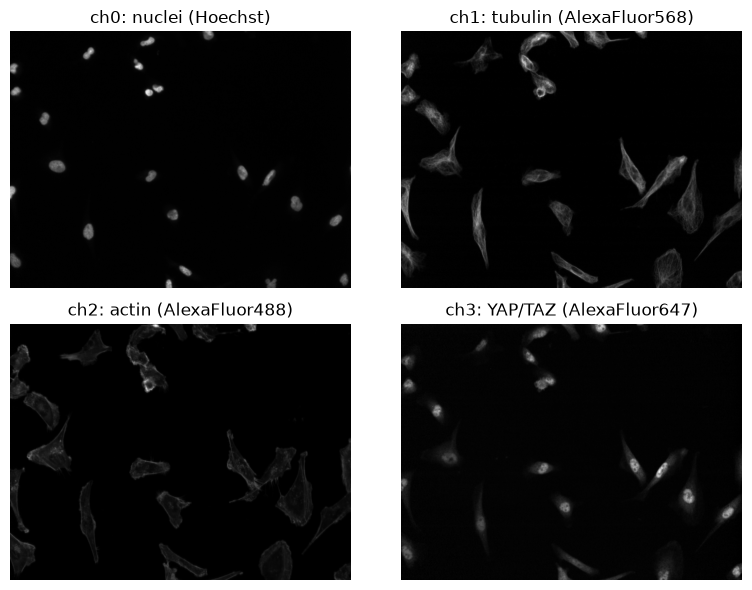

In [20]:
# display all channels 
fig, axs = plt.subplots(2, 2, figsize=(8,6))

axs[0, 0].imshow(im_all[0,], cmap='gray')
axs[0, 0].set_title('ch0: nuclei (Hoechst)')
axs[0, 0].axis('off')

axs[0, 1].imshow(im_all[1,], cmap='gray')
axs[0, 1].set_title('ch1: tubulin (AlexaFluor568)')
axs[0, 1].axis('off')

axs[1, 0].imshow(im_all[2,], cmap='gray')
axs[1, 0].set_title('ch2: actin (AlexaFluor488)')
axs[1, 0].axis('off')

axs[1, 1].imshow(im_all[3,], cmap='gray')
axs[1, 1].set_title('ch3: YAP/TAZ (AlexaFluor647)')
axs[1, 1].axis('off')

plt.tight_layout()

# Using napari in a jupyter notebook
We can interact with *napari* through a jupyter notebook. To start:

In [22]:
import napari

In [23]:
# Create and run the napari viewer
viewer = napari.Viewer()

In [27]:
# add image to napari
viewer.add_image(im_all, channel_axis=0)

[<Image layer 'Image' at 0x336d0d1f0>,
 <Image layer 'Image [1]' at 0x3334d3500>,
 <Image layer 'Image [2]' at 0x33348b080>,
 <Image layer 'Image [3]' at 0x3333f99a0>]

<br> 

#### _Rocco will guide you in the following session on how to do so!_

<br>

# Additional exercises
Some extra tasks to practice what we've just covered.

<div style="background-color:#699AD6; border-radius: 5px; padding: 10pt"><strong>Task 1</strong> Assign the value 25 to the variable <code>age</code> in the cell below - what type is this variable?</div>

<div style="background-color:#699AD6; border-radius: 5px; padding: 10pt"><strong>Task 2</strong> Create a new variable named <code>height_cm</code> that converts the value of <code>height_m</code> from meters to centimeters. (Hint hint: you have to multiply by 100!) </div>

<div style="background-color:#699AD6; border-radius: 5px; padding: 10pt"><strong>Task 3</strong> Create a new numerical array named <code>birthdays</code> where the first row contains the day, month, and year of your birthday, and the second row contains the day, month, and year of the person currently sitting next to you. Can you tell us how many years apart were you born? Were you born on the same month?</div>

### Additional exercises – for loop
Let's start with a couple of examples:

In [ ]:
array1D = np.array([2, 5, 8])

sum_elements = 0
for element in array1D:
    print('\nStarting value for sum for this iteration', sum_elements)
    sum_elements = sum_elements + element
    print('End value for sum for this iteration', sum_elements)

print('\nThe sum of all elements in the array is', sum_elements) 

In [ ]:
array1D = np.array([2, 5, 8])

sum_elements = 0
for l in range(len(array1D)):
    print('\nStarting value for sum for iteration number', l, 'is', sum_elements)
    sum_elements = sum_elements + array1D[l]
    print('End value for sum for iteration number', l, 'is', sum_elements)

print('\nThe sum of all elements in the array is', sum_elements) 
print('The loop performed', len(array1D), 'iterations')

Now give it a try!

<div style="background-color:#699AD6; border-radius: 5px; padding: 10pt"><strong>Task 4</strong> Write a loop that calculates the sum of elements in a numerical array by adding each element and printing the final value </div>

### Further reading
If you're interested in knowing more about basics of Python coding, there are a lot of free resources out there! A good one to start with, that inspired the content of this notebook, it's offered by the [Software Carpentries](https://software-carpentry.org/) and can be found [at this link](https://swcarpentry.github.io/python-novice-inflammation/).
